# DDPG on Lunar Lander: OU vs Gaussian exploration noise

Continuous Lunar Lander in Gymnasium. DDPG is implemented from scratch in PyTorch and trained with two exploration noises.

## Setup

In [1]:
import subprocess
import sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "swig"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium[box2d]"], check=True)
print("Install finished")

Install finished


In [2]:
import hashlib
import json
import multiprocessing as mp
import os
import random
import time
import warnings
from concurrent.futures import ProcessPoolExecutor, wait

import gymnasium as gym
import imageio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from IPython.display import Image, clear_output, display

torch.set_num_threads(1)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/lunar_lander_ddpg_v3"
except ImportError:
    OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

print("CPU cores:", os.cpu_count())

Mounted at /content/drive
CPU cores: 2


## Hyperparameters

Noise std decays from `noise_start` to `noise_end` after a random warm-up. Episode counts include the warm-up episodes. Saved runs are reused only when every setting except `seeds` and `resume` is unchanged.

In [3]:
CFG = dict(
    episodes=500,
    seeds=[0, 1, 2, 3, 4],
    gamma=0.99,
    batch_size=128,
    buffer_size=100_000,
    hidden=256,
    actor_lr=1e-4,
    critic_lr=1e-3,
    tau=0.005,
    grad_clip=1.0,
    warmup_steps=5000,
    noise_start=0.5,
    noise_end=0.1,
    noise_decay=0.99,
    update_every=1,
    eval_every=10,
    eval_episodes=5,
    final_eval_episodes=20,
    resume=True,
)
NAMES = {"ou": "OU noise", "gauss": "Gaussian noise"}

pd.Series(CFG, name="value").to_frame()

,value
episodes,500
seeds,"[0, 1, 2, 3, 4]"
gamma,0.99
batch_size,128
buffer_size,100000
hidden,256
actor_lr,0.0001
critic_lr,0.001
tau,0.005
grad_clip,1.0


## Implementation

In [4]:
def make_lunar_lander(render_mode=None):
    candidates = [
        ("LunarLanderContinuous-v3", {}),
        ("LunarLander-v3", {"continuous": True})
    ]
    errors = []
    for env_id, kwargs in candidates:
        try:
            env = gym.make(env_id, render_mode=render_mode, **kwargs)
        except Exception as e:
            errors.append(f"  {env_id} {kwargs}: {type(e).__name__}: {e}")
            continue
        if not isinstance(env.action_space, gym.spaces.Box):
            errors.append(f"  {env_id} {kwargs}: action space is not continuous")
            env.close()
            continue
        return env
    raise RuntimeError("Could not create a continuous Lunar Lander. Attempts:\n" + "\n".join(errors))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [5]:
class ReplayBuffer:
    def __init__(self, capacity, state_size, action_size):
        self.capacity = capacity
        self.states = np.zeros((capacity, state_size), dtype=np.float32)
        self.actions = np.zeros((capacity, action_size), dtype=np.float32)
        self.rewards = np.zeros((capacity, 1), dtype=np.float32)
        self.next_states = np.zeros((capacity, state_size), dtype=np.float32)
        self.dones = np.zeros((capacity, 1), dtype=np.float32)
        self.size = 0
        self.position = 0

    def insert(self, state, action, reward, next_state, done):
        i = self.position
        self.states[i] = state
        self.actions[i] = action
        self.rewards[i] = reward
        self.next_states[i] = next_state
        self.dones[i] = done
        self.size = min(self.size + 1, self.capacity)
        self.position = (i + 1) % self.capacity

    def sample(self, batch_size):
        idx = np.random.randint(0, self.size, size=batch_size)
        return (
            torch.from_numpy(self.states[idx]),
            torch.from_numpy(self.actions[idx]),
            torch.from_numpy(self.rewards[idx]),
            torch.from_numpy(self.next_states[idx]),
            torch.from_numpy(self.dones[idx]),
        )

    def __len__(self):
        return self.size

In [6]:
class ActorNet(nn.Module):
    def __init__(self, input_size, output_size, hidden):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, output_size), nn.Tanh(),
        )

    def forward(self, x):
        return self.net(x)


class CriticNet(nn.Module):
    def __init__(self, input_size, hidden):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, state, action):
        return self.net(torch.cat((state, action), dim=1))

In [ ]:
class OUProcess:
    def __init__(self, dimension, theta=0.2, dt=1.0):
        self.dimension = dimension
        self.theta = theta
        self.dt = dt
        self.amplitude = 0.0
        self.reset()

    def set_std(self, std):
        # std = amplitude / sqrt(theta*dt*(2 - theta*dt))
        self.amplitude = std * np.sqrt(self.theta * self.dt * (2 - self.theta * self.dt))

    def reset(self):
        self.state = np.zeros(self.dimension)

    def sample(self):
        dw = np.random.normal(size=self.dimension)
        self.state = self.state - self.theta * self.state * self.dt + self.amplitude * dw
        return self.state.copy()


class GaussianNoise:
    def __init__(self, dimension):
        self.dimension = dimension
        self.std = 0.0

    def set_std(self, std):
        self.std = std

    def reset(self):
        pass

    def sample(self):
        return np.random.normal(scale=self.std, size=self.dimension)


def make_noise(process, dimension):
    return {"ou": OUProcess, "gauss": GaussianNoise}[process](dimension)

In [8]:
def evaluate_policy(agent, env, n_episodes, seed):
    returns, lengths = [], []
    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed + ep)
        done, total, steps = False, 0.0, 0
        while not done:
            state, reward, terminated, truncated, _ = env.step(agent.select_action(state))
            total += reward
            steps += 1
            done = terminated or truncated
        returns.append(total)
        lengths.append(steps)
    return np.array(returns), np.array(lengths)


class Agent:
    def __init__(self, env, cfg):
        self.env = env
        self.cfg = cfg
        self.state_size = env.observation_space.shape[0]
        self.action_size = env.action_space.shape[0]
        self.action_low = env.action_space.low
        self.action_high = env.action_space.high
        self.total_steps = 0

        h = cfg["hidden"]
        self.replay_buffer = ReplayBuffer(cfg["buffer_size"], self.state_size, self.action_size)
        self.actor = ActorNet(self.state_size, self.action_size, h)
        self.critic = CriticNet(self.state_size + self.action_size, h)
        self.target_actor = ActorNet(self.state_size, self.action_size, h).eval()
        self.target_critic = CriticNet(self.state_size + self.action_size, h).eval()
        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr=cfg["actor_lr"])
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=cfg["critic_lr"])

        for p in list(self.target_actor.parameters()) + list(self.target_critic.parameters()):
            p.requires_grad_(False)
        self._actor_params = list(self.actor.parameters())
        self._critic_params = list(self.critic.parameters())
        self._target_actor_params = list(self.target_actor.parameters())
        self._target_critic_params = list(self.target_critic.parameters())
        self.update_target_networks(tau=1.0)

    @torch.no_grad()
    def update_target_networks(self, tau):
        torch._foreach_mul_(self._target_actor_params, 1.0 - tau)
        torch._foreach_add_(self._target_actor_params, self._actor_params, alpha=tau)
        torch._foreach_mul_(self._target_critic_params, 1.0 - tau)
        torch._foreach_add_(self._target_critic_params, self._critic_params, alpha=tau)

    def act(self, state):
        with torch.inference_mode():
            return self.actor(torch.from_numpy(np.asarray(state, dtype=np.float32))).numpy()

    def select_action(self, state, noise=None):
        action = self.act(state)
        if noise is not None:
            action = action + noise.sample()
        return np.clip(action, self.action_low, self.action_high).astype(np.float32)

    def update(self):
        cfg = self.cfg
        states, actions, rewards, next_states, dones = self.replay_buffer.sample(cfg["batch_size"])

        with torch.no_grad():
            next_q = self.target_critic(next_states, self.target_actor(next_states))
            targets = rewards + cfg["gamma"] * (1.0 - dones) * next_q

        critic_loss = F.mse_loss(self.critic(states, actions), targets)
        self.critic_optimizer.zero_grad(set_to_none=True)
        critic_loss.backward()
        nn.utils.clip_grad_norm_(self._critic_params, cfg["grad_clip"])
        self.critic_optimizer.step()

        actor_loss = -self.critic(states, self.actor(states)).mean()
        self.actor_optimizer.zero_grad(set_to_none=True)
        actor_loss.backward(inputs=self._actor_params)
        self.actor_optimizer.step()

        self.update_target_networks(cfg["tau"])
        return actor_loss.item(), critic_loss.item()

    def train(self, process, seed, callback=None):
        cfg = self.cfg
        noise = make_noise(process, self.action_size)
        eval_env = make_lunar_lander()
        rewards, lengths, actor_losses, critic_losses, clip_frac = [], [], [], [], []
        eval_x, eval_curve = [], []
        learn_eps = 0

        for eps in range(1, cfg["episodes"] + 1):
            noise.set_std(max(cfg["noise_end"], cfg["noise_start"] * cfg["noise_decay"] ** learn_eps))
            noise.reset()
            state, _ = self.env.reset(seed=seed) if eps == 1 else self.env.reset()

            done, ep_return, steps = False, 0.0, 0
            clipped, acting = 0, 0
            a_sum, c_sum, n_updates = 0.0, 0.0, 0

            while not done:
                if self.total_steps < cfg["warmup_steps"]:
                    action = self.env.action_space.sample()
                else:
                    raw = self.act(state) + noise.sample()
                    action = np.clip(raw, self.action_low, self.action_high).astype(np.float32)
                    clipped += int(np.sum((raw < self.action_low) | (raw > self.action_high)))
                    acting += 1

                next_state, reward, terminal, truncated, _ = self.env.step(action)
                done = terminal or truncated
                self.replay_buffer.insert(state, action, reward, next_state, float(terminal))
                self.total_steps += 1
                ep_return += reward
                steps += 1

                if (self.total_steps >= cfg["warmup_steps"]
                        and len(self.replay_buffer) >= cfg["batch_size"]
                        and self.total_steps % cfg["update_every"] == 0):
                    a_loss, c_loss = self.update()
                    a_sum += a_loss
                    c_sum += c_loss
                    n_updates += 1

                state = next_state

            learn_eps += int(self.total_steps >= cfg["warmup_steps"])
            rewards.append(ep_return)
            lengths.append(steps)
            actor_losses.append(a_sum / n_updates if n_updates else np.nan)
            critic_losses.append(c_sum / n_updates if n_updates else np.nan)
            clip_frac.append(clipped / (acting * self.action_size) if acting else np.nan)

            if eps % cfg["eval_every"] == 0:
                returns, _ = evaluate_policy(self, eval_env, cfg["eval_episodes"], seed=5000)
                eval_x.append(eps)
                eval_curve.append(returns.mean())
            if callback is not None:
                callback(eps, ep_return)

        final_returns, final_lengths = evaluate_policy(self, eval_env, cfg["final_eval_episodes"], seed=1000)
        eval_env.close()
        return dict(
            rewards=np.array(rewards), lengths=np.array(lengths),
            actor=np.array(actor_losses), critic=np.array(critic_losses),
            clip_frac=np.array(clip_frac),
            eval_x=np.array(eval_x), eval_curve=np.array(eval_curve),
            eval_final=final_returns, eval_final_len=final_lengths,
        )

In [9]:
def run_testing_and_create_gif(agent, gif_path, seed=0, fps=20):
    env = make_lunar_lander(render_mode="rgb_array")
    state, _ = env.reset(seed=seed)
    done, total, frames = False, 0.0, []
    while not done:
        state, reward, terminated, truncated, _ = env.step(agent.select_action(state))
        total += reward
        frames.append(env.render())
        done = terminated or truncated
    env.close()
    print(f"total_reward: {total:.1f}, steps: {len(frames)}")
    imageio.mimsave(gif_path, frames, fps=fps)


def build_agent_from_state(actor_state, cfg):
    agent = Agent(make_lunar_lander(), {**cfg, "buffer_size": 10})
    agent.actor.load_state_dict(actor_state)
    return agent

In [10]:
def cfg_tag(cfg):
    keys = {k: v for k, v in cfg.items() if k not in ("seeds", "resume")}
    return hashlib.md5(json.dumps(keys, sort_keys=True).encode()).hexdigest()[:8]


def job_path(process, seed, cfg):
    return os.path.join(OUT_DIR, f"{process}_seed{seed}_{cfg_tag(cfg)}")


def run_job(process, seed, cfg, progress=None):
    torch.set_num_threads(1)
    set_seed(seed)
    env = make_lunar_lander()
    env.action_space.seed(seed)
    agent = Agent(env, cfg)
    key = f"{process}-seed{seed}"

    def report(eps, ret):
        if progress is not None:
            progress[key] = (eps, ret)

    out = agent.train(process, seed, callback=report)
    env.close()

    path = job_path(process, seed, cfg)
    np.savez(path + ".npz", **out)
    actor_state = {k: v.clone() for k, v in agent.actor.state_dict().items()}
    torch.save(actor_state, path + ".pt")
    return dict(process=process, seed=seed, actor_state=actor_state, **out)


def load_job(process, seed, cfg):
    path = job_path(process, seed, cfg)
    data = np.load(path + ".npz")
    run = {k: data[k] for k in data.files}
    return dict(process=process, seed=seed, actor_state=torch.load(path + ".pt"), **run)


def show_progress(progress, todo, t0, episodes):
    clear_output(wait=True)
    print(f"Elapsed: {(time.time() - t0) / 60:.1f} min")
    for process, seed in todo:
        key = f"{process}-seed{seed}"
        eps, ret = progress.get(key, (0, float("nan")))
        print(f"{key:12s} episode {eps:4d}/{episodes}   last return {ret:8.1f}")


def run_all(cfg, n_workers=None):
    jobs = [(p, s) for s in cfg["seeds"] for p in NAMES]
    finished, todo = {}, []
    for p, s in jobs:
        path = job_path(p, s, cfg)
        if cfg["resume"] and os.path.exists(path + ".npz") and os.path.exists(path + ".pt"):
            finished[(p, s)] = load_job(p, s, cfg)
            print(f"Loaded saved run: {p} seed {s}")
        else:
            todo.append((p, s))

    if todo:
        n_workers = n_workers or min(os.cpu_count() or 1, len(todo))
        print(f"Running {len(todo)} runs with {n_workers} parallel workers")
        ctx = mp.get_context("fork")
        t0 = time.time()
        with ctx.Manager() as manager:
            progress = manager.dict()
            with ProcessPoolExecutor(max_workers=n_workers, mp_context=ctx) as ex:
                futures = {ex.submit(run_job, p, s, cfg, progress): (p, s) for p, s in todo}
                pending = set(futures)
                while pending:
                    done, pending = wait(pending, timeout=15)
                    for f in done:
                        finished[futures[f]] = f.result()
                    show_progress(progress, todo, t0, cfg["episodes"])
        print(f"All runs finished in {(time.time() - t0) / 60:.1f} min")

    return {p: [finished[(p, s)] for s in cfg["seeds"]] for p in NAMES}

## Smoke test

Three short episodes to check that everything runs and to measure speed.

In [11]:
smoke_cfg = {**CFG, "episodes": 3, "warmup_steps": 150, "eval_every": 1,
             "eval_episodes": 1, "final_eval_episodes": 1}
set_seed(0)
smoke_env = make_lunar_lander()
smoke_agent = Agent(smoke_env, smoke_cfg)

t0 = time.time()
smoke_out = smoke_agent.train("ou", seed=0)
dt = time.time() - t0
print(f"{smoke_agent.total_steps} env steps in {dt:.1f}s, about {smoke_agent.total_steps / dt:.0f} steps/s")
smoke_env.close()

pd.DataFrame({k: smoke_out[k] for k in ("rewards", "lengths", "actor", "critic", "clip_frac")},
             index=range(1, 4))

302 env steps in 1.2s, about 257 steps/s


,rewards,lengths,actor,critic,clip_frac
1,38.983047,80,NaN,NaN,NaN
2,-390.362731,139,-0.405134,114.297923,0.15942
3,-779.557002,83,1.304931,100.878598,0.46988


## Run the experiment

In [12]:
results = run_all(CFG)

Elapsed: 135.2 min
ou-seed0     episode  500/500   last return     34.9
gauss-seed0  episode  500/500   last return    255.0
ou-seed1     episode  500/500   last return    269.3
gauss-seed1  episode  500/500   last return   -190.8
ou-seed2     episode  500/500   last return    209.4
gauss-seed2  episode  500/500   last return    266.2
ou-seed3     episode  500/500   last return    271.9
gauss-seed3  episode  500/500   last return    209.4
ou-seed4     episode  500/500   last return    255.7
gauss-seed4  episode  500/500   last return    297.3
All runs finished in 135.2 min


## Results

### Per-seed results

`pct_eval_ge_200` is the share of noise-free test episodes with a return of at least 200.

In [13]:
rows = []
for process, name in NAMES.items():
    for r in results[process]:
        rows.append({
            "method": name,
            "seed": r["seed"],
            "train_return_last50": r["rewards"][-50:].mean(),
            "eval_return": r["eval_final"].mean(),
            "pct_eval_ge_200": 100 * np.mean(r["eval_final"] >= 200),
            "critic_loss_last50": np.nanmean(r["critic"][-50:]),
            "clipped_actions_pct": 100 * np.nanmean(r["clip_frac"][-50:]),
        })
per_seed = pd.DataFrame(rows).round(1)
per_seed

,method,seed,train_return_last50,eval_return,pct_eval_ge_200,critic_loss_last50,clipped_actions_pct
0,OU noise,0,193.8,21.2,50.0,248.3,7.8
1,OU noise,1,270.9,245.1,80.0,19.8,12.1
2,OU noise,2,179.0,205.8,85.0,29.0,5.7
3,OU noise,3,185.2,-20.4,35.0,130.3,8.1
4,OU noise,4,227.1,256.6,90.0,22.4,8.3
5,Gaussian noise,0,140.0,1.4,15.0,41.1,8.8
6,Gaussian noise,1,-190.3,-204.0,0.0,45355.6,10.6
7,Gaussian noise,2,60.2,156.6,55.0,7369.9,13.1
8,Gaussian noise,3,153.7,210.5,70.0,17.1,9.2
9,Gaussian noise,4,206.5,160.5,60.0,23.7,6.8


### Summary (mean and std over seeds)

In [14]:
summary = per_seed.drop(columns="seed").groupby("method").agg(["mean", "std"]).round(1).T
summary

method                    Gaussian noise  OU noise
train_return_last50 mean            74.0     211.2
                    std            156.8      38.2
eval_return         mean            65.0     141.7
                    std            169.6     131.1
pct_eval_ge_200     mean            40.0      68.0
                    std             30.6      24.1
critic_loss_last50  mean         10561.5      90.0
                    std          19708.7      99.9
clipped_actions_pct mean             9.7       8.4
                    std              2.3       2.3

### Plots

In [15]:
def smooth(x, window):
    return pd.Series(x).rolling(window, min_periods=1).mean().to_numpy()


def plot_metric(key, ylabel, title, filename, x_key=None, window=1, log_y=False, hline=None):
    plt.figure(figsize=(8, 5))
    for process, label in NAMES.items():
        curves = np.array([smooth(r[key], window) for r in results[process]])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            mean, std = np.nanmean(curves, axis=0), np.nanstd(curves, axis=0)
        x = results[process][0][x_key] if x_key else np.arange(1, curves.shape[1] + 1)
        plt.plot(x, mean, label=label)
        plt.fill_between(x, mean - std, mean + std, alpha=0.2)
    if hline is not None:
        plt.axhline(hline, color="gray", linestyle="--", linewidth=1)
    if log_y:
        plt.yscale("log")
    plt.title(title)
    plt.xlabel("Episodes")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, filename), dpi=150)
    plt.show()

#### Training return (10-episode moving average)

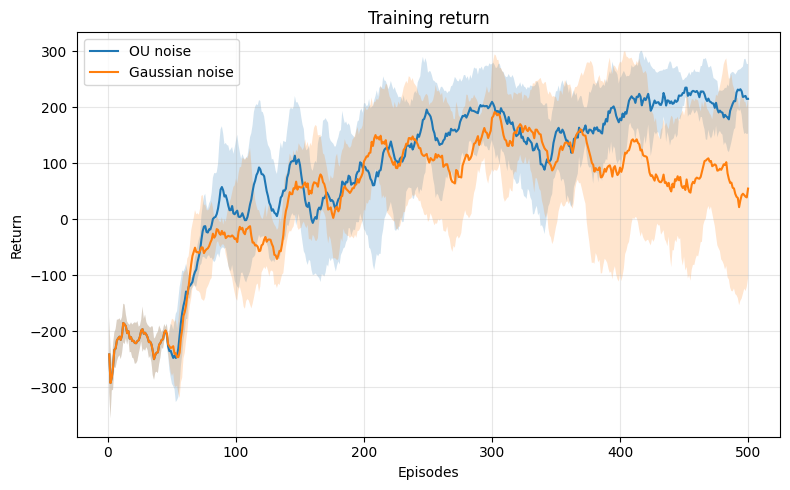

In [16]:
plot_metric("rewards", "Return", "Training return", "train_return.png", window=10)

#### Noise-free evaluation during training

The dashed line at 200 is the usual threshold for solving the task.

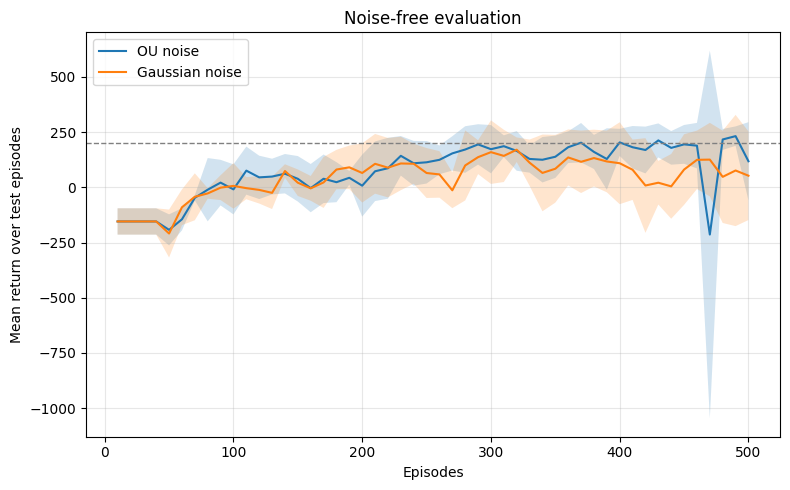

In [17]:
plot_metric("eval_curve", "Mean return over test episodes", "Noise-free evaluation",
            "eval_return.png", x_key="eval_x", hline=200)

#### Critic loss

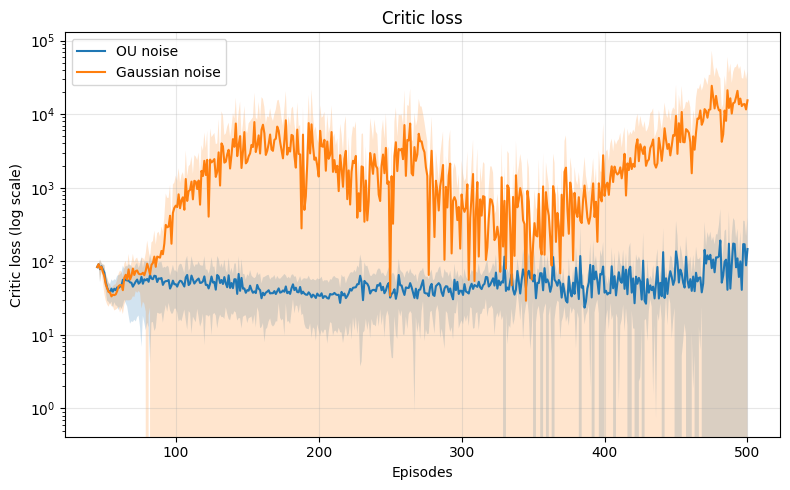

In [18]:
plot_metric("critic", "Critic loss (log scale)", "Critic loss", "critic_loss.png", log_y=True)

#### Actor loss

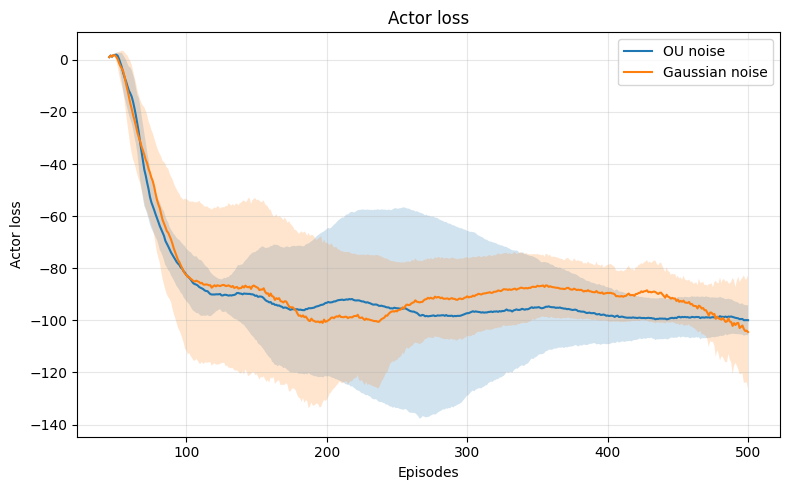

In [19]:
plot_metric("actor", "Actor loss", "Actor loss", "actor_loss.png")

#### Share of actions clipped at the bounds (10-episode moving average)

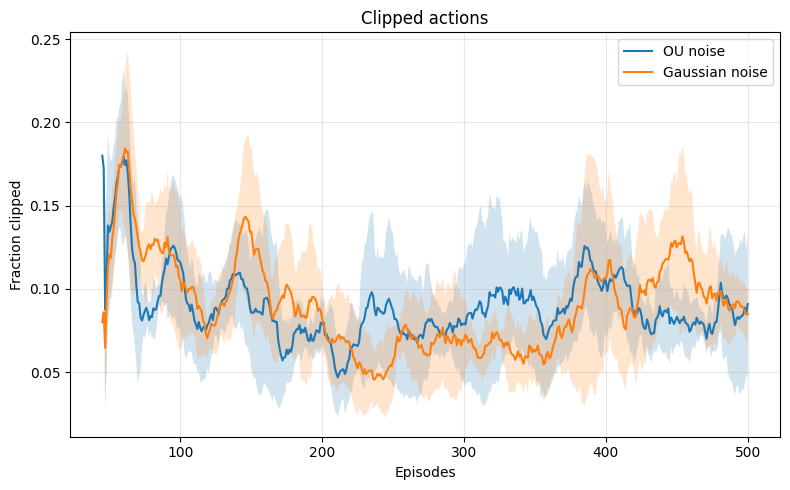

In [20]:
plot_metric("clip_frac", "Fraction clipped", "Clipped actions", "clipped_actions.png", window=10)

#### Episode length (10-episode moving average)

The time limit is 1000 steps.

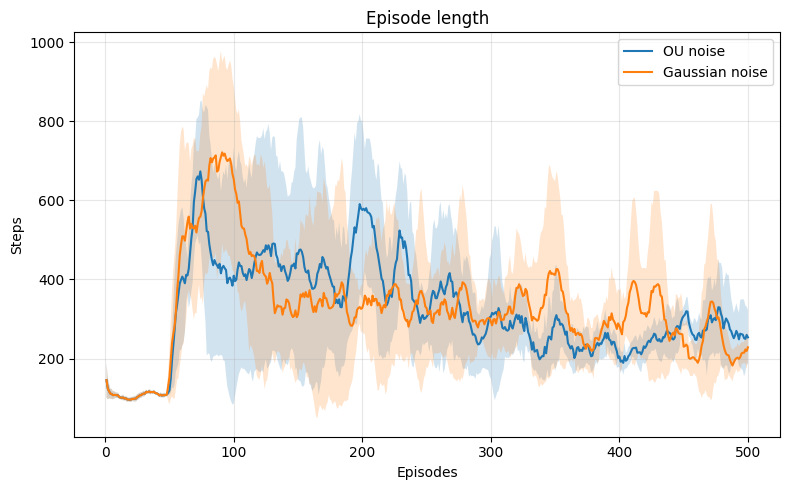

In [21]:
plot_metric("lengths", "Steps", "Episode length", "episode_length.png", window=10)

### Final noise-free evaluation

Boxes pool all test episodes across seeds. Black dots are per-seed means.

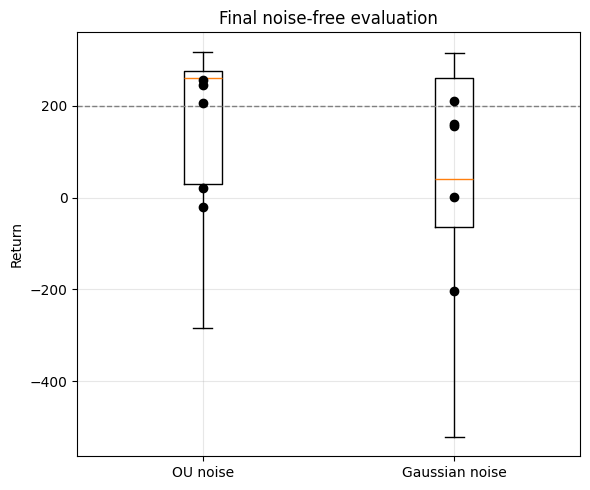

In [22]:
fig, ax = plt.subplots(figsize=(6, 5))
data = [np.concatenate([r["eval_final"] for r in results[p]]) for p in NAMES]
ax.boxplot(data, showfliers=False)
for i, p in enumerate(NAMES, start=1):
    means = [r["eval_final"].mean() for r in results[p]]
    ax.scatter([i] * len(means), means, color="black", zorder=3)
ax.axhline(200, color="gray", linestyle="--", linewidth=1)
ax.set_xticks([1, 2])
ax.set_xticklabels(list(NAMES.values()))
ax.set_ylabel("Return")
ax.set_title("Final noise-free evaluation")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "final_eval.png"), dpi=150)
plt.show()

### Trained policies

The seed with the highest final evaluation return for each method.

OU, seed 4
total_reward: 313.5, steps: 154


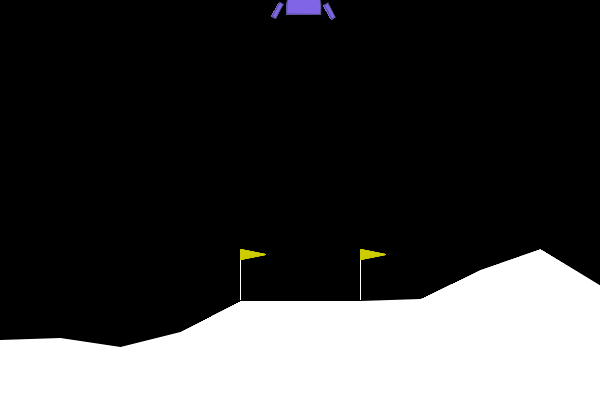

In [25]:
best = max(results["ou"], key=lambda r: r["eval_final"].mean())
print("OU, seed", best["seed"])
agent = build_agent_from_state(best["actor_state"], CFG)
gif_path = os.path.join(OUT_DIR, "lander_ou.gif")
run_testing_and_create_gif(agent, gif_path)
Image(filename=gif_path)

Gaussian, seed 3
total_reward: -30.7, steps: 318


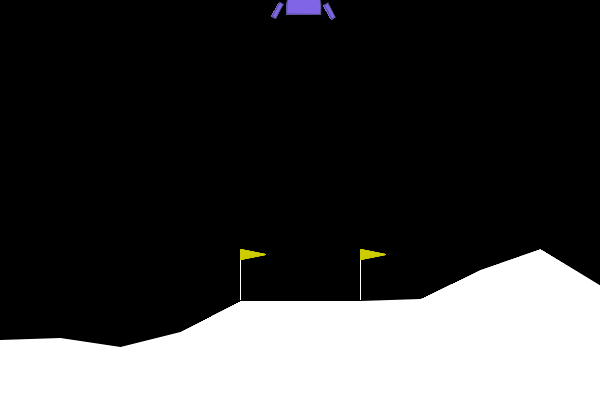

In [27]:
best = max(results["gauss"], key=lambda r: r["eval_final"].mean())
print("Gaussian, seed", best["seed"])
agent = build_agent_from_state(best["actor_state"], CFG)
gif_path = os.path.join(OUT_DIR, "lander_gauss.gif")
run_testing_and_create_gif(agent, gif_path)
Image(filename=gif_path)